In [1]:
import sys
sys.path.append('..')
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from src.data_prep import filter_residential, trim_price_outliers

sns.set_palette('colorblind')
df = pd.read_csv('../data/processed/london_house_prices.csv', parse_dates=['date_of_transfer'])
df.shape

(302729, 18)

## missingness

saon/locality nulls are expected (not every address has a sub-unit or locality). price/date/postcode/coords are the fields that matter and have zero nulls.

In [2]:
df.isnull().mean().sort_values(ascending=False)

locality             0.936468
saon                 0.623066
street               0.000020
lat                  0.000000
record_status        0.000000
ppd_category_type    0.000000
county               0.000000
district             0.000000
town_city            0.000000
transaction_id       0.000000
price                0.000000
paon                 0.000000
duration             0.000000
old_new              0.000000
property_type        0.000000
postcode             0.000000
date_of_transfer     0.000000
long                 0.000000
dtype: float64

## category type / property type

category b (repossessions, buy-to-lets, transfers under power of sale) and property_type o (commercial/other) carry extreme non-residential prices, up to £793m. plan scope is residential avm, so these get filtered out via `filter_residential`.

In [3]:
df.groupby('ppd_category_type')['price'].describe()

,count,mean,std,min,25%,50%,75%,max
ppd_category_type,,,,,,,,
A,241179.0,7.192215e+05,1.431864e+06,1.0,395000.0,530000.0,763220.0,540000000.0
B,61550.0,1.132541e+06,6.077833e+06,100.0,290000.0,427260.5,662000.0,793020000.0


In [4]:
df = filter_residential(df)
df.shape, df['price'].describe()

((241179, 18),
 count    2.411790e+05
 mean     7.192215e+05
 std      1.431864e+06
 min      1.000000e+00
 25%      3.950000e+05
 50%      5.300000e+05
 75%      7.632200e+05
 max      5.400000e+08
 Name: price, dtype: float64)

## price outliers within category a

category a still has £1 transfers (non-arm's-length, e.g. family gifts) and at least one clear data error (a £540m terraced house in E4). floor + top-0.1% trim via `trim_price_outliers`; the remaining upper tail (£10-75m, mostly SW1X/W2/W11 flats) is plausible prime-london stock, kept as is.

In [5]:
df = trim_price_outliers(df)
df.shape, df['price'].describe()

((240932, 18),
 count    2.409320e+05
 mean     6.990964e+05
 std      6.636754e+05
 min      4.650000e+04
 25%      3.950000e+05
 50%      5.300000e+05
 75%      7.600252e+05
 max      1.110000e+07
 Name: price, dtype: float64)

## price distribution

raw price is heavily right-skewed (typical for house prices) -- log scale is closer to normal and is what the models will target.

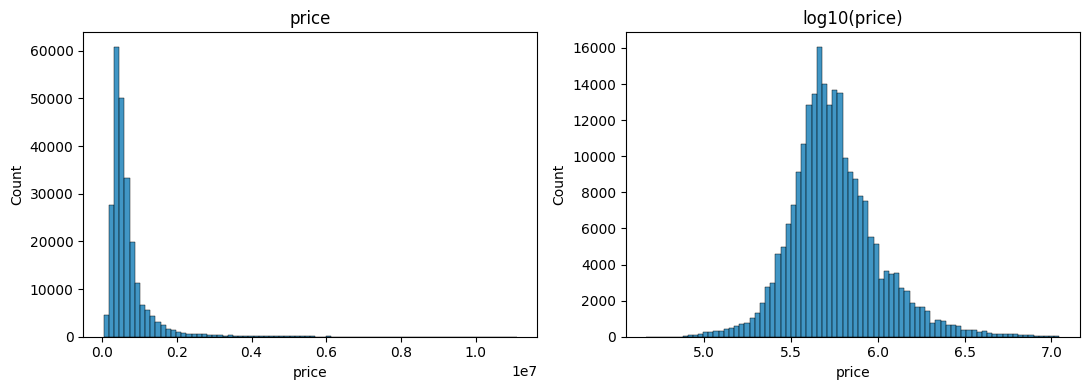

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(df['price'], bins=80, ax=axes[0])
axes[0].set_title('price')
sns.histplot(df['price'].apply('log10'), bins=80, ax=axes[1])
axes[1].set_title('log10(price)')
plt.tight_layout()

## price trend over time

monthly median, by property type.

Text(0.5, 1.0, 'greater london monthly median price by property type')

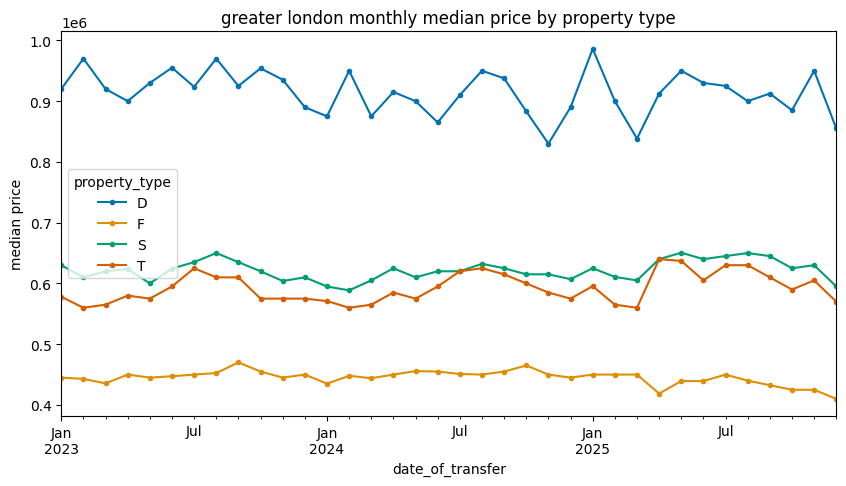

In [7]:
monthly = df.groupby([df['date_of_transfer'].dt.to_period('M'), 'property_type'])['price'].median().unstack()
monthly.index = monthly.index.to_timestamp()
monthly.plot(figsize=(10, 5), marker='o', markersize=3)
plt.ylabel('median price')
plt.title('greater london monthly median price by property type')

## geographic scatter

sampled points (full set is too dense to render), colored by log price.

In [8]:
sample = df.sample(8000, random_state=0).copy()
sample['log_price'] = sample['price'].apply('log10')
fig = px.scatter_map(
    sample, lat='lat', lon='long', color='log_price',
    color_continuous_scale='viridis', map_style='carto-positron',
    zoom=8.5, height=650, opacity=0.6,
)
fig.show()